# Week 3 on Kaggle: the reviewer's soundness tests

Same tests as the Colab week-3 notebook, adapted for Kaggle's free GPU.

**Before you run:**
1. Right panel → **Settings**: **Accelerator = GPU T4 x2**, **Internet = On** (Kaggle asks you to verify your phone once).
2. Your data comes in one of two ways (step 0 finds it automatically):
   - **A (recommended):** the `fyp_kaggle.zip` you made in Google Drive, shared as "Anyone with the link". Paste that link into `DRIVE_ZIP_LINK` in step 0.
   - **B:** upload the same folders as a private Kaggle Dataset and add it with **Add Input**.
3. **Run All.** Everything is written to `/kaggle/working/fyp_pilot/week3/`. Steps that already finished on Colab are skipped, as long as your `week3` folder was included.
4. At the end, step 14 prints the summary. Copy that box and send it to Claude, or download `week3_summary.txt` from the Output panel.

In [3]:
#@title 0 · Kaggle: fetch your data and lay it out like the Drive folder
DRIVE_ZIP_LINK = 'https://drive.google.com/file/d/1pzQ1AoDFrY682zaKn8lEorvy7sv8vE7Z/view?usp=sharing'

import os, glob, shutil, subprocess
OUTP = '/kaggle/working/fyp_pilot'
SEARCH = ['/kaggle/input']
if DRIVE_ZIP_LINK:
    subprocess.run(['pip', '-q', 'install', 'gdown'], check=True)
    import gdown
    os.makedirs('/tmp/_in', exist_ok=True)
    if not os.path.exists('/tmp/fyp_kaggle.zip'):
        gdown.download(url=DRIVE_ZIP_LINK, output='/tmp/fyp_kaggle.zip', fuzzy=True, quiet=False)
    if not glob.glob('/tmp/_in/**/subset.csv', recursive=True):
        subprocess.run(['unzip', '-q', '-o', '/tmp/fyp_kaggle.zip', '-d', '/tmp/_in'], check=True)
    SEARCH.insert(0, '/tmp/_in')

def find(pattern, dirs=False):
    hits = []
    for root in SEARCH:
        hits += [h for h in glob.glob(f'{root}/**/{pattern}', recursive=True) if os.path.isdir(h) == dirs]
    return sorted(hits)

os.makedirs(OUTP, exist_ok=True)
sub = find('subset.csv'); assert sub, 'subset.csv not found: check the zip link (option A) or Add Input (option B).'
shutil.copy(sub[0], f'{OUTP}/subset.csv')
import pandas as _pd
first = _pd.read_csv(sub[0]).utt.iloc[0]
flac = find(f'{first}.flac'); assert flac, f'audio subset not found (looked for {first}.flac)'
if not os.path.exists(f'{OUTP}/subset'):
    os.symlink(os.path.dirname(flac[0]), f'{OUTP}/subset')
ck = find('Best_LA_model_for_DF.pth'); assert ck, 'Best_LA_model_for_DF.pth not found'
os.makedirs(f'{OUTP}/checkpoints', exist_ok=True)
if not os.path.exists(f'{OUTP}/checkpoints/Best_LA_model_for_DF.pth'):
    os.symlink(ck[0], f'{OUTP}/checkpoints/Best_LA_model_for_DF.pth')
sc = [h for h in find('dev__clean.csv') if os.path.basename(os.path.dirname(h)) == 'scores' and '/run_' not in h]
assert sc, 'scores/dev__clean.csv not found (checkpoint A scores from weeks 1-2)'
shutil.copytree(os.path.dirname(sc[0]), f'{OUTP}/scores', dirs_exist_ok=True)
lay = find('layers_clean.npz'); assert lay, 'week2/inside_A/layers_clean.npz not found'
os.makedirs(f'{OUTP}/week2', exist_ok=True)
if not os.path.exists(f'{OUTP}/week2/inside_A'):
    os.symlink(os.path.dirname(lay[0]), f'{OUTP}/week2/inside_A')
w3 = [d for d in find('week3', dirs=True) if not d.startswith(OUTP)]
if w3:
    shutil.copytree(w3[0], f'{OUTP}/week3', dirs_exist_ok=True)
print('subset:', os.path.dirname(flac[0])); print('checkpoint:', ck[0]); print('scores:', os.path.dirname(sc[0]))
print('layers:', os.path.dirname(lay[0])); print('earlier week-3 results:', w3[0] if w3 else 'none (starting fresh)')

Downloading...
From (original): https://drive.google.com/uc?id=1pzQ1AoDFrY682zaKn8lEorvy7sv8vE7Z
From (redirected): https://drive.google.com/uc?id=1pzQ1AoDFrY682zaKn8lEorvy7sv8vE7Z&confirm=t&uuid=f0b0f127-5e8b-44a7-89a1-18f6d2c751b8
To: /tmp/fyp_kaggle.zip
100%|██████████| 1.72G/1.72G [01:05<00:00, 26.5MB/s]


subset: /tmp/_in/fyp_pilot/subset
checkpoint: /tmp/_in/fyp_pilot/checkpoints/Best_LA_model_for_DF.pth
scores: /tmp/_in/fyp_pilot/scores
layers: /tmp/_in/fyp_pilot/week2/inside_A
earlier week-3 results: none (starting fresh)


In [4]:
#@title 1 · Settings and Google Drive (week 3)
import os, json, time, glob
CFG = dict(
    SEED=1234, BATCH=16,
    OUT='/kaggle/working/fyp_pilot',      # the week-1 folder
    WORK='/kaggle/working/work',
    RUN_DETECTORS=['A', 'B', 'AASIST'],          # A = Best_LA_model_for_DF.pth, B = LA_model.pth, AASIST = Jung et al.
    INSIDE_CKPTS=['A'],                          # steps 7-9; add 'B' only if you have spare time
    INSIDE_LAYERS=[5, 11, 17, 23],               # layers (0-23) used for the test-time fix in step 9
    RESCORE_FOR_LLR=True,                        # re-score week-1 stages once to also save the 'fake' logit
    # Optional: folder in your Drive with the Mendeley ElevenLabs/Respeecher clips (unzipped). '' = skip.
    ELEVEN_DIR='',
    # ---- week 3 ----
    CAND_LAYERS=[3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],   # candidate layers for the fit-half choice
    GATE_LAYER=3,                                             # early layer used by the phone-call gate
    N_BOOT=1000,                                              # bootstrap resamples for 95% intervals
    DO_2021=True,                                             # step 13: ASVspoof 2021 LA (about 7.6 GB download)
    N21=120,                                                  # 2021 LA utterances per codec and class
)
for d in (CFG['WORK'], f"{CFG['OUT']}/figures", f"{CFG['OUT']}/week2"):
    os.makedirs(d, exist_ok=True)
assert os.path.exists(f"{CFG['OUT']}/subset.csv"), 'Week-1 folder not found: run the week-1 notebook first, or fix CFG["OUT"].'
print(json.dumps(CFG, indent=1))

{
 "SEED": 1234,
 "BATCH": 16,
 "OUT": "/kaggle/working/fyp_pilot",
 "WORK": "/kaggle/working/work",
 "RUN_DETECTORS": [
  "A",
  "B",
  "AASIST"
 ],
 "INSIDE_CKPTS": [
  "A"
 ],
 "INSIDE_LAYERS": [
  5,
  11,
  17,
  23
 ],
 "RESCORE_FOR_LLR": true,
 "ELEVEN_DIR": "",
 "CAND_LAYERS": [
  3,
  5,
  7,
  9,
  11,
  13,
  15,
  17,
  19,
  21,
  23
 ],
 "GATE_LAYER": 3,
 "N_BOOT": 1000,
 "DO_2021": true,
 "N21": 120
}


In [5]:
#@title 2 · Install packages and codecs
!pip -q install transformers soundfile pandas matplotlib scikit-learn webrtc-noise-gain
!apt-get -qq install -y opus-tools > /dev/null
import subprocess, re, shutil
def encoders(ff='ffmpeg'):
    out = subprocess.run([ff, '-hide_banner', '-encoders'], capture_output=True, text=True).stdout
    return {n for n in ('libgsm', 'libopus', 'pcm_mulaw', 'libopencore_amrnb', 'libvo_amrwbenc') if re.search(rf'\s{n}\s', out)}
FFMPEG, enc = 'ffmpeg', encoders()
FFMPEG_GSM = 'ffmpeg' if 'libgsm' in enc else None          # Colab's own ffmpeg has GSM
if 'libopencore_amrnb' not in enc:                          # ... but not AMR: use the static build, as in week 1
    if not os.path.exists('/kaggle/working/ffs/ffmpeg'):
        !wget -q -O /kaggle/working/ffs.tar.xz https://johnvansickle.com/ffmpeg/releases/ffmpeg-release-amd64-static.tar.xz
        !mkdir -p /kaggle/working/ffs && tar -xf /kaggle/working/ffs.tar.xz -C /kaggle/working/ffs --strip-components=1
    if os.path.exists('/kaggle/working/ffs/ffmpeg') and 'libopencore_amrnb' in encoders('/kaggle/working/ffs/ffmpeg'):
        FFMPEG, enc = '/kaggle/working/ffs/ffmpeg', encoders('/kaggle/working/ffs/ffmpeg')
HAVE_OPUS_TOOLS = shutil.which('opusenc') is not None and shutil.which('opusdec') is not None
try:
    import webrtc_noise_gain; HAVE_WEBRTC = True
except Exception as e:
    HAVE_WEBRTC = False; print('WebRTC processing not available:', e)
print('ffmpeg:', FFMPEG, '| encoders:', sorted(enc), '| GSM via:', FFMPEG_GSM)
print('opus-tools:', HAVE_OPUS_TOOLS, '| WebRTC:', HAVE_WEBRTC, '| AMR-WB:', 'libvo_amrwbenc' in enc)
assert 'libopencore_amrnb' in enc, 'AMR-NB encoder missing: the static ffmpeg download failed. Rerun this cell.'

ffmpeg: /kaggle/working/ffs/ffmpeg | encoders: ['libopencore_amrnb', 'libopus', 'libvo_amrwbenc', 'pcm_mulaw'] | GSM via: ffmpeg
opus-tools: True | WebRTC: True | AMR-WB: True


In [6]:
#@title 3 · Code and checkpoints (SSL-AASIST from your Drive, AASIST from GitHub)
REPO = '/kaggle/working/SSL_Anti-spoofing'
if not os.path.exists(REPO):
    !git clone -q --depth 1 https://github.com/TakHemlata/SSL_Anti-spoofing {REPO}
AREPO = '/kaggle/working/aasist'
if not os.path.exists(AREPO):
    !git clone -q --depth 1 https://github.com/clovaai/aasist {AREPO}
commit = lambda r: subprocess.run(['git', '-C', r, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
COMMITS = {'SSL_Anti-spoofing': commit(REPO), 'aasist': commit(AREPO)}
cks = sorted(glob.glob(f"{CFG['OUT']}/checkpoints/**/*.pth", recursive=True))
CK = {'A': next((p for p in cks if os.path.basename(p) == 'Best_LA_model_for_DF.pth'), None),
      'B': next((p for p in cks if os.path.basename(p) == 'LA_model.pth'), None)}
print('commits:', COMMITS)
print('SSL-AASIST checkpoints:', {k: (os.path.basename(v) if v else None) for k, v in CK.items()})
assert CK['A'], 'Best_LA_model_for_DF.pth not found under fyp_pilot/checkpoints (it was downloaded in week 1).'
if not CK['B'] and 'B' in CFG['RUN_DETECTORS']:
    print('LA_model.pth not found: checkpoint B will be skipped.'); CFG['RUN_DETECTORS'].remove('B')

commits: {'SSL_Anti-spoofing': '4acaa61dcef5f7610f43aa4d0b29c4559b970cd2', 'aasist': 'a04c9863f63d44471dde8a6abcb3b082b07cd1d1'}
SSL-AASIST checkpoints: {'A': 'Best_LA_model_for_DF.pth', 'B': None}
LA_model.pth not found: checkpoint B will be skipped.


In [7]:
#@title 4 · The week-1 audio subset (from Drive)
import numpy as np, pandas as pd
SUB = f"{CFG['OUT']}/subset"
subset = pd.read_csv(f"{CFG['OUT']}/subset.csv")
subset['path'] = SUB + '/' + subset.utt + '.flac'
missing = [p for p in subset.path if not os.path.exists(p)]
assert not missing, f'{len(missing)} subset files missing, e.g. {missing[:3]}'
EV, DV = subset[subset.part == 'eval'].reset_index(drop=True), subset[subset.part == 'dev'].reset_index(drop=True)
print(subset.groupby(['part', 'label']).size().rename('n'))
print('eval speakers:', EV.speaker.nunique())

part  label
dev   0         498
      1         500
eval  0         988
      1        1000
Name: n, dtype: int64
eval speakers: 67


In [8]:
%%writefile /kaggle/working/pilot_lib.py
# ---------------------------------------------------------------------------
# Pilot library: call-stage simulator, alignment, SSL-AASIST loader, metrics.
# Kept in one file so it can be tested outside Colab and pasted into the notebook.
# ---------------------------------------------------------------------------
import os, re, sys, types, json, zlib, shutil, tempfile, subprocess
import numpy as np
import soundfile as sf
from scipy.signal import butter, sosfiltfilt, correlate

SR = 16000
CUT = 64600          # SSL-AASIST input length (~4.04 s), as in Tak et al.'s code


# ----------------------------- audio helpers ------------------------------
def tak_pad(x, max_len=CUT):
    """Exactly Tak et al.'s pad(): truncate, or tile short clips."""
    if len(x) >= max_len:
        return x[:max_len]
    reps = int(max_len / len(x)) + 1
    return np.tile(x, reps)[:max_len]


def _run(cmd):
    r = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    if r.returncode != 0:
        raise RuntimeError(' '.join(cmd) + '\n' + r.stderr.decode(errors='ignore')[-800:])


def ffmpeg_roundtrip(x, enc_args, codec_sr=8000, ext='wav', ffmpeg='ffmpeg'):
    """16 kHz float -> (resample to codec_sr) -> encode -> decode -> 16 kHz float."""
    with tempfile.TemporaryDirectory() as d:
        inp, mid, out = f'{d}/in.wav', f'{d}/mid.{ext}', f'{d}/out.wav'
        sf.write(inp, np.clip(x, -1, 1), SR, subtype='PCM_16')
        _run([ffmpeg, '-y', '-loglevel', 'error', '-i', inp, '-ac', '1', '-ar', str(codec_sr)] + enc_args + [mid])
        _run([ffmpeg, '-y', '-loglevel', 'error', '-i', mid, '-ac', '1', '-ar', str(SR), '-c:a', 'pcm_f32le', out])
        y, _ = sf.read(out, dtype='float32')
    return y


def align_to(ref, y, max_lag=1600):
    """Remove codec delay: find the lag that best matches ref, shift y, trim/pad to len(ref)."""
    n = min(len(ref), len(y), 2 * SR)
    a, b = ref[:n].astype(np.float64), y[:n].astype(np.float64)
    if np.std(a) < 1e-8 or np.std(b) < 1e-8:
        lag = 0
    else:
        c = correlate(b, a, mode='full', method='fft')
        lags = np.arange(-n + 1, n)
        keep = np.abs(lags) <= max_lag
        lag = int(lags[keep][np.argmax(c[keep])])
    if lag > 0:
        y = y[lag:]
    elif lag < 0:
        y = np.concatenate([np.zeros(-lag, dtype=y.dtype), y])
    if len(y) < len(ref):
        y = np.concatenate([y, np.zeros(len(ref) - len(y), dtype=y.dtype)])
    return y[:len(ref)].astype(np.float32), lag


def bandpass(x, lo=300, hi=3400, order=6):
    sos = butter(order, [lo, hi], btype='bandpass', fs=SR, output='sos')
    return sosfiltfilt(sos, x).astype(np.float32)   # zero-phase: no delay


def rms_normalise(x, target_dbfs=-26.0):
    rms = np.sqrt(np.mean(x ** 2)) + 1e-12
    y = x * (10 ** (target_dbfs / 20) / rms)
    peak = np.max(np.abs(y))
    return (y / peak * 0.99 if peak > 0.99 else y).astype(np.float32)


def frame_loss(x, utt_id, rate, seed, frame=320, fade=40):
    """Drop 20 ms frames at random (seeded per utterance) and conceal by repeating
    the previous frame, attenuated, with short cross-fades. A simplified packet-loss
    concealment, documented as such; not the G.711 Appendix I algorithm."""
    rng = np.random.default_rng((zlib.crc32(utt_id.encode()) ^ seed) & 0xFFFFFFFF)
    y = x.copy()
    n = len(x) // frame
    lost = rng.random(n) < rate
    ramp = np.linspace(0, 1, fade, dtype=np.float32)
    run = 0
    for i in range(1, n):
        s = i * frame
        if lost[i]:
            run += 1
            seg = y[s - frame:s] * (0.7 ** run)          # repeat the last frame, attenuated
            seg[:fade] = y[s - 1] * (1 - ramp) + seg[:fade] * ramp   # smooth join, no click
            y[s:s + frame] = seg
        else:
            if run:   # fade back in from the concealed frame
                y[s:s + fade] = y[s - fade:s] * (1 - ramp) + x[s:s + fade] * ramp
            run = 0
    return y, float(lost.mean())


# ----------------------------- conditions ---------------------------------
def available_encoders(ffmpeg='ffmpeg'):
    out = subprocess.run([ffmpeg, '-hide_banner', '-encoders'], stdout=subprocess.PIPE, stderr=subprocess.PIPE).stdout.decode()
    return {name for name in ('libgsm', 'libopus', 'pcm_mulaw', 'libopencore_amrnb', 'libvo_amrwbenc') if re.search(rf'\s{name}\s', out)}


def make_conditions(encoders, seed, ffmpeg='ffmpeg'):
    """Returns {name: (description, fn(x, utt_id) -> (y, info))}. Every output is
    16 kHz, the same length as the input and sample-aligned with it."""
    C = {}
    C['clean'] = ('No processing', lambda x, u: (x, {}))
    C['clean_rms'] = ('Clean, loudness-normalised to -26 dBFS (loudness/AGC control)',
                      lambda x, u: (rms_normalise(x), {}))
    C['bandpass_300_3400'] = ('Telephone band 300-3,400 Hz, zero-phase filter (band-limit control)',
                              lambda x, u: (bandpass(x), {}))

    def coded(args, ext, sr=8000):
        def fn(x, u):
            y, lag = align_to(x, ffmpeg_roundtrip(x, args, sr, ext, ffmpeg))
            return y, {'lag': lag}
        return fn

    C['nb_resample'] = ('16 -> 8 -> 16 kHz resampling only (control for all 8 kHz codecs)',
                        coded(['-c:a', 'pcm_s16le'], 'wav'))
    if 'pcm_mulaw' in encoders:
        C['g711u'] = ('G.711 mu-law, 64 kbps', coded(['-c:a', 'pcm_mulaw'], 'wav'))

        def g711_loss(x, u):
            y, info = C['g711u'][1](x, u)
            y, lost = frame_loss(y, u, 0.10, seed)
            return y, dict(info, lost=lost)
        C['g711u_loss10'] = ('G.711 mu-law with 10% 20 ms frame loss, repetition concealment', g711_loss)
    if 'libgsm' in encoders:
        C['gsm_fr'] = ('GSM full-rate, 13 kbps (2G mobile)', coded(['-c:a', 'libgsm'], 'gsm'))
    if 'libopencore_amrnb' in encoders:
        C['amrnb_12k2'] = ('AMR-NB 12.2 kbps (mobile)', coded(['-c:a', 'libopencore_amrnb', '-b:a', '12.2k'], 'amr'))
        C['amrnb_4k75'] = ('AMR-NB 4.75 kbps (mobile, low rate)', coded(['-c:a', 'libopencore_amrnb', '-b:a', '4.75k'], 'amr'))
    if 'libopus' in encoders:
        C['opus_nb_8k'] = ('Opus narrowband, 8 kbps, VoIP mode',
                           coded(['-c:a', 'libopus', '-b:a', '8k', '-application', 'voip'], 'opus'))
    return C


# ----------------------------- metrics ------------------------------------
def det_curve(tar, non):
    """Identical to Tak et al.'s compute_det_curve (target = bona fide)."""
    n = tar.size + non.size
    s = np.concatenate([tar, non]); l = np.concatenate([np.ones(tar.size), np.zeros(non.size)])
    idx = np.argsort(s, kind='mergesort'); l = l[idx]
    tsum = np.cumsum(l); nsum = non.size - (np.arange(1, n + 1) - tsum)
    frr = np.concatenate([[0], tsum / tar.size]); far = np.concatenate([[1], nsum / non.size])
    thr = np.concatenate([[s[idx[0]] - 0.001], s[idx]])
    return frr, far, thr


def eer(tar, non):
    frr, far, thr = det_curve(tar, non)
    i = np.argmin(np.abs(frr - far))
    return float(np.mean([frr[i], far[i]])), float(thr[i])


def rates_at(tar, non, t):
    """Bona fide rejected (false alarm on a real caller) and spoof accepted (miss), at threshold t.
    A score >= t is accepted as bona fide."""
    return float(np.mean(tar < t)), float(np.mean(non >= t))


def dcf(p_fa_bona, p_miss_spoof, p_spoof, c_rej_bona=1.0, c_acc_spoof=10.0):
    """Normalised detection cost. 'Rejecting bona fide' and 'accepting spoof' are the two errors.
    Defaults follow ASVspoof 5 (C=1 and 10, P_spoof=0.05)."""
    cost = c_rej_bona * (1 - p_spoof) * p_fa_bona + c_acc_spoof * p_spoof * p_miss_spoof
    return float(cost / min(c_rej_bona * (1 - p_spoof), c_acc_spoof * p_spoof))


def min_dcf(tar, non, p_spoof, c1=1.0, c2=10.0):
    frr, far, _ = det_curve(tar, non)
    return float(min(dcf(fr, fa, p_spoof, c1, c2) for fr, fa in zip(frr, far)))


def boot_ci(d, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, d.size, replace=True).mean() for _ in range(n)]
    return float(np.mean(d)), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))


PRIORS = {'asv5': (0.05, 1.0, 10.0), 'balanced': (0.5, 1.0, 1.0)}


def summarise(scores, clean, thr):
    """scores/clean: DataFrames indexed by utt with columns score, label(1=bona fide), correct_clean."""
    out = {}
    for subset, mask in (('all', np.ones(len(scores), bool)), ('clean_correct', scores['correct_clean'].values)):
        s = scores[mask]; c = clean.loc[s.index]
        tar, non = s[s.label == 1].score.values, s[s.label == 0].score.values
        if tar.size < 2 or non.size < 2:          # e.g. an empty clean-correct subset
            out[subset] = {'eer': np.nan, 'fa_bona_at_thr': np.nan, 'miss_spoof_at_thr': np.nan,
                           'n_bona': int(tar.size), 'n_spoof': int(non.size)}
            continue
        e, _ = eer(tar, non)
        fa, miss = rates_at(tar, non, thr)
        r = {'eer': e, 'fa_bona_at_thr': fa, 'miss_spoof_at_thr': miss, 'hter_at_thr': (fa + miss) / 2}
        for k, (p, c1, c2) in PRIORS.items():
            r[f'minDCF_{k}'] = min_dcf(tar, non, p, c1, c2)
            r[f'actDCF_{k}'] = dcf(fa, miss, p, c1, c2)
            r[f'calib_loss_{k}'] = r[f'actDCF_{k}'] - r[f'minDCF_{k}']
        for lab, name in ((1, 'bona'), (0, 'spoof')):
            d = (s[s.label == lab].score.values - c[c.label == lab].score.values)
            m, lo, hi = boot_ci(d)
            r[f'shift_{name}_mean'], r[f'shift_{name}_lo'], r[f'shift_{name}_hi'] = m, lo, hi
        r['n_bona'], r['n_spoof'] = int(tar.size), int(non.size)
        out[subset] = r
    return out


def decision(row_clean, row):
    """Pre-registered pilot rule: clean EER <= 5% AND (EER rises >= 10 points OR
    real callers rejected at the transferred threshold rise >= 15 points)."""
    ok_clean = row_clean['eer'] <= 0.05
    d_eer = row['eer'] - row_clean['eer']
    d_fa = row['fa_bona_at_thr'] - row_clean['fa_bona_at_thr']
    counts = ok_clean and (d_eer >= 0.10 or d_fa >= 0.15)
    if not counts:
        kind = 'no_effect'
    elif d_eer >= 0.10:
        kind = 'ranking_breaks'
    else:
        kind = 'threshold_only'
    return counts, kind, d_eer, d_fa


# ----------------------------- model loader -------------------------------
def xlsr_config(n_layers=24, conv_bias=True):
    from transformers import Wav2Vec2Config
    return Wav2Vec2Config(
        hidden_size=1024, num_hidden_layers=n_layers, num_attention_heads=16, intermediate_size=4096,
        hidden_act='gelu', hidden_dropout=0.0, activation_dropout=0.0, attention_dropout=0.0,
        feat_proj_dropout=0.0, final_dropout=0.0, layerdrop=0.0, layer_norm_eps=1e-5,
        feat_extract_norm='layer', feat_extract_activation='gelu', conv_dim=(512,) * 7,
        conv_stride=(5, 2, 2, 2, 2, 2, 2), conv_kernel=(10, 3, 3, 3, 3, 2, 2), conv_bias=conv_bias,
        num_conv_pos_embeddings=128, num_conv_pos_embedding_groups=16, do_stable_layer_norm=True,
        apply_spec_augment=False, mask_time_prob=0.0, mask_feature_prob=0.0)


IGNORED_FS_PREFIXES = ('quantizer.', 'project_q.', 'final_proj.', 'project_inp.', 'target_glu.', 'input_quantizer.', 'mask_emb')


def map_fairseq_to_hf(sd_fs, hf_keys):
    """Rename fairseq wav2vec 2.0 parameter names to Hugging Face Wav2Vec2Model names.
    Module names checked against the fairseq commit bundled in Tak et al.'s repository."""
    hf_keys = set(hf_keys)
    param_wn = any('parametrizations.weight.original0' in k for k in hf_keys)
    out, unused = {}, []
    for k, v in sd_fs.items():
        nk = None
        if m := re.fullmatch(r'feature_extractor\.conv_layers\.(\d+)\.0\.(weight|bias)', k):
            nk = f'feature_extractor.conv_layers.{m[1]}.conv.{m[2]}'
        elif m := re.fullmatch(r'feature_extractor\.conv_layers\.(\d+)\.2\.1\.(weight|bias)', k):
            nk = f'feature_extractor.conv_layers.{m[1]}.layer_norm.{m[2]}'
        elif k in ('layer_norm.weight', 'layer_norm.bias'):
            nk = 'feature_projection.' + k
        elif m := re.fullmatch(r'post_extract_proj\.(weight|bias)', k):
            nk = f'feature_projection.projection.{m[1]}'
        elif k == 'encoder.pos_conv.0.bias':
            nk = 'encoder.pos_conv_embed.conv.bias'
        elif k == 'encoder.pos_conv.0.weight_g':
            nk = 'encoder.pos_conv_embed.conv.' + ('parametrizations.weight.original0' if param_wn else 'weight_g')
        elif k == 'encoder.pos_conv.0.weight_v':
            nk = 'encoder.pos_conv_embed.conv.' + ('parametrizations.weight.original1' if param_wn else 'weight_v')
        elif m := re.fullmatch(r'encoder\.layers\.(\d+)\.(.+)', k):
            rest = (m[2].replace('self_attn_layer_norm', 'layer_norm').replace('self_attn.', 'attention.')
                    .replace('fc1.', 'feed_forward.intermediate_dense.').replace('fc2.', 'feed_forward.output_dense.'))
            nk = f'encoder.layers.{m[1]}.{rest}'
        elif k in ('encoder.layer_norm.weight', 'encoder.layer_norm.bias'):
            nk = k
        elif k == 'mask_emb':
            nk = 'masked_spec_embed'
        if nk is None or nk not in hf_keys:
            unused.append(k)
        else:
            out[nk] = v
    missing = sorted(hf_keys - set(out))
    return out, unused, missing


def build_ssl_aasist(repo_dir, ckpt_path, device='cpu'):
    """Tak et al.'s SSL-AASIST with the fairseq front-end replaced by an identical
    Hugging Face Wav2Vec2Model, so no fairseq install is needed. Loads strictly."""
    import torch, torch.nn as nn
    from transformers import Wav2Vec2Model
    sd = torch.load(ckpt_path, map_location='cpu')
    if isinstance(sd, dict) and 'state_dict' in sd and isinstance(sd['state_dict'], dict):
        sd = sd['state_dict']
    sd = {k[7:] if k.startswith('module.') else k: v for k, v in sd.items()}
    pre = 'ssl_model.model.'
    fs = {k[len(pre):]: v for k, v in sd.items() if k.startswith(pre)}
    n_layers = 1 + max(int(m[1]) for k in fs if (m := re.match(r'encoder\.layers\.(\d+)\.', k)))
    conv_bias = 'feature_extractor.conv_layers.0.0.bias' in fs
    cfg = xlsr_config(n_layers, conv_bias)

    class HFSSL(nn.Module):
        def __init__(self, device):
            super().__init__()
            self.model = Wav2Vec2Model(cfg)
            self.out_dim = cfg.hidden_size
            self.device = device

        def extract_feat(self, x, output_hidden_states=False):
            if x.ndim == 3:
                x = x[:, :, 0]
            o = self.model(x, output_hidden_states=output_hidden_states)
            if output_hidden_states:
                self.last_hidden_states = o.hidden_states
            return o.last_hidden_state

    if 'fairseq' not in sys.modules:                 # model.py imports fairseq at the top; never used here
        sys.modules['fairseq'] = types.ModuleType('fairseq')
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)
    import model as tak
    tak.SSLModel = HFSSL
    net = tak.Model(None, device)
    hf_keys = list(net.ssl_model.model.state_dict().keys())
    mapped, unused, missing = map_fairseq_to_hf(fs, hf_keys)
    bad_unused = [k for k in unused if not k.startswith(IGNORED_FS_PREFIXES)]
    missing = [k for k in missing if k != 'masked_spec_embed']
    if bad_unused or missing:
        raise RuntimeError(f'Weight mapping failed.\nUnmapped checkpoint keys: {bad_unused[:20]}\nMissing model keys: {missing[:20]}')
    full = {k: v for k, v in sd.items() if not k.startswith(pre)}
    full.update({pre + k: v for k, v in mapped.items()})
    if 'masked_spec_embed' in hf_keys and 'masked_spec_embed' not in mapped:   # only exists in some versions
        full[pre + 'masked_spec_embed'] = net.ssl_model.model.masked_spec_embed.detach()
    net.load_state_dict(full, strict=True)
    report = {'xlsr_layers': n_layers, 'conv_bias': conv_bias, 'ssl_params_loaded': len(mapped),
              'ignored_pretraining_params': len(unused), 'backend_params_loaded': len(sd) - len(fs)}
    return net.to(device).eval(), report


# ===========================================================================
# Week 2 additions: shortcut controls, more realistic channels, a second
# architecture (AASIST) and hooks for looking inside the XLS-R front end.
# ===========================================================================
def trim_bounds(x, frame=320, rel_db=-35.0, margin=1600):
    """Start/end sample of the speech region: frames within rel_db of the loudest
    20 ms frame, padded by 100 ms. Computed on the CLEAN copy and applied to the
    call copy too, so the pair stays aligned (silence-shortcut control)."""
    n = max(1, len(x) // frame)
    e = np.array([np.mean(x[i * frame:(i + 1) * frame] ** 2) for i in range(n)]) + 1e-12
    db = 10 * np.log10(e / e.max())
    idx = np.where(db > rel_db)[0]
    if idx.size == 0:
        return 0, len(x)
    return max(0, idx[0] * frame - margin), min(len(x), (idx[-1] + 1) * frame + margin)


def opus_plc(x, loss_pct, bitrate_k=8, opusenc='opusenc', opusdec='opusdec', ffmpeg='ffmpeg'):
    """Opus narrowband speech at bitrate_k kbit/s with real Opus packet-loss concealment
    (opusdec --packet-loss). opusdec draws losses from an unseeded rand(), so the loss
    pattern is deterministic and identical for every file: documented, reproducible."""
    with tempfile.TemporaryDirectory() as d:
        sf.write(f'{d}/in.wav', np.clip(x, -1, 1), SR, subtype='PCM_16')
        _run([ffmpeg, '-y', '-loglevel', 'error', '-i', f'{d}/in.wav', '-ac', '1', '-ar', '8000', f'{d}/in8.wav'])
        _run([opusenc, '--quiet', '--bitrate', str(bitrate_k), '--speech', '--framesize', '20', f'{d}/in8.wav', f'{d}/a.opus'])
        _run([opusdec, '--quiet', '--rate', str(SR), '--packet-loss', str(loss_pct), f'{d}/a.opus', f'{d}/o.wav'])
        y, _ = sf.read(f'{d}/o.wav', dtype='float32')
    if y.ndim > 1:
        y = y[:, 0]
    return y


def webrtc_apm(x, noise_suppression=2, auto_gain_dbfs=3):
    """WebRTC noise suppression + automatic gain control (+ its high-pass filter), as phones
    and VoIP apps apply before encoding. 10 ms chunks of 16 kHz int16."""
    from webrtc_noise_gain import AudioProcessor
    ap = AudioProcessor(auto_gain_dbfs, noise_suppression)
    pcm = (np.clip(x, -1, 1) * 32767).astype(np.int16)
    n = len(pcm) // 160 * 160
    out = bytearray()
    for i in range(0, n, 160):
        out += ap.Process10ms(pcm[i:i + 160].tobytes()).audio
    y = np.frombuffer(bytes(out), dtype=np.int16).astype(np.float32) / 32768
    return np.concatenate([y, np.zeros(len(x) - len(y), np.float32)])


def _coded(args, ext, sr, ffmpeg):
    def fn(x, u):
        y, lag = align_to(x, ffmpeg_roundtrip(x, args, sr, ext, ffmpeg))
        return y, {'lag': lag}
    return fn


def frame_loss_ge(x, utt_id, mean_loss, mean_burst, seed, frame=320, fade=40):
    """Bursty 20 ms frame loss from a two-state Gilbert-Elliott chain (seeded per utterance), with the
    same repetition concealment as frame_loss. mean_loss = long-run loss rate, mean_burst = frames per burst."""
    rng = np.random.default_rng((zlib.crc32(utt_id.encode()) ^ (seed + 7)) & 0xFFFFFFFF)
    p_bg = 1.0 / mean_burst                       # bad -> good
    p_gb = mean_loss * p_bg / (1 - mean_loss)     # good -> bad
    n = len(x) // frame
    lost, bad = np.zeros(n, bool), False
    for i in range(n):
        bad = (rng.random() < p_gb) if not bad else (rng.random() >= p_bg)
        lost[i] = bad
    lost[0] = False
    y = x.copy(); ramp = np.linspace(0, 1, fade, dtype=np.float32); run = 0
    for i in range(1, n):
        s = i * frame
        if lost[i]:
            run += 1
            seg = y[s - frame:s] * (0.7 ** run)
            seg[:fade] = y[s - 1] * (1 - ramp) + seg[:fade] * ramp
            y[s:s + frame] = seg
        else:
            if run:
                y[s:s + fade] = y[s - fade:s] * (1 - ramp) + x[s:s + fade] * ramp
            run = 0
    return y, float(lost.mean())


def make_conditions_v2(encoders, seed, ffmpeg='ffmpeg', ffmpeg_gsm=None, have_opus_tools=False, have_webrtc=False):
    """Week-2 stages. Returns {name: (description, fn(x, utt_id) -> (y, info))}.
    Shortcut controls (names with __rms / __trim) are added later, per damaging stage."""
    base = make_conditions(encoders, seed, ffmpeg)
    C = {}
    if ffmpeg_gsm and 'libgsm' in available_encoders(ffmpeg_gsm):
        def gsm(x, u):
            y, lag = align_to(x, ffmpeg_roundtrip(x, ['-c:a', 'libgsm'], 8000, 'gsm', ffmpeg_gsm))
            return y, {'lag': lag}
        C['gsm_fr'] = ('GSM full-rate, 13 kbit/s (2G mobile)', gsm)
    if have_opus_tools:
        for p in (5, 10, 20):
            def f(x, u, p=p):
                y, lag = align_to(x, opus_plc(x, p, ffmpeg=ffmpeg))
                return y, {'lag': lag, 'lost': p / 100}
            C[f'opus_nb_8k_plc{p}'] = (f'Opus 8 kbit/s, {p}% packet loss, native Opus concealment', f)
    if have_webrtc and 'amrnb_12k2' in base:
        def apm_amr(x, u):
            w, lag = align_to(x, webrtc_apm(x))          # WebRTC adds a short delay: remove it first
            y, info = base['amrnb_12k2'][1](w, u)
            return y, dict(info, lag=lag + info.get('lag', 0))
        C['webrtc_amrnb_12k2'] = ('WebRTC noise suppression + gain control, then AMR-NB 12.2 kbit/s', apm_amr)
        def apm(x, u):
            y, lag = align_to(x, webrtc_apm(x))
            return y, {'lag': lag}
        C['webrtc_only'] = ('WebRTC noise suppression + gain control only', apm)
    if 'libopencore_amrnb' in encoders:                      # dose-response over AMR-NB rates
        for r in ('5.9', '7.4'):
            C[f"amrnb_{r.replace('.', 'k')}"] = (f'AMR-NB {r} kbit/s (mobile)', _coded(['-c:a', 'libopencore_amrnb', '-b:a', f'{r}k'], 'amr', 8000, ffmpeg))
    if 'libvo_amrwbenc' in encoders:                         # wideband (HD voice / VoLTE)
        for r in ('12.65', '23.85'):
            C[f"amrwb_{r.replace('.', 'k')}"] = (f'AMR-WB {r} kbit/s (HD voice, 16 kHz)', _coded(['-c:a', 'libvo_amrwbenc', '-b:a', f'{r}k'], 'amr', 16000, ffmpeg))
    if 'libopus' in encoders:                                # wideband VoIP, as WebRTC apps normally run
        for r in (16, 24):
            C[f'opus_wb_{r}k'] = (f'Opus wideband {r} kbit/s, VoIP mode', _coded(['-c:a', 'libopus', '-b:a', f'{r}k', '-application', 'voip'], 'opus', 16000, ffmpeg))
    if 'g711u' in base:                                      # bursty (Gilbert-Elliott) loss, mean burst 3 frames
        for m in (5, 10):
            def ge(x, u, m=m):
                y, info = base['g711u'][1](x, u)
                y, lost = frame_loss_ge(y, u, m / 100, 3.0, seed)
                return y, dict(info, lost=lost)
            C[f'g711u_burst{m}'] = (f'G.711 with {m}% bursty frame loss (Gilbert-Elliott, mean burst 60 ms)', ge)
    if 'amrnb_12k2' in base:
        def chain(x, u):
            y, info = base['amrnb_12k2'][1](bandpass(x), u)
            y, lost = frame_loss(y, u, 0.05, seed)
            return y, dict(info, lost=lost)
        C['chain_bp_amr12k2_loss5'] = ('Band-limit, AMR-NB 12.2 kbit/s, 5% frame loss', chain)
    return base, C


def shortcut_variants(stage_fn):
    """Loudness and silence controls applied AFTER the call stage (B in the mechanism slide).
    __rms : call copy loudness-normalised to -26 dBFS.
    __trim: clean-defined speech region cut from the call copy (leading/trailing silence removed)."""
    def rms(x, u):
        y, info = stage_fn(x, u)
        return rms_normalise(y), info
    def trim(x, u):
        y, info = stage_fn(x, u)
        s, e = trim_bounds(x)
        return y[s:e], dict(info, trim=(s, e))
    return rms, trim


def clean_trim(x, u):
    s, e = trim_bounds(x)
    return x[s:e], {'trim': (s, e)}


# ----------------------------- second architecture ------------------------
def build_aasist(repo_dir, device='cpu', variant='AASIST'):
    """Jung et al.'s released AASIST (raw-waveform, no SSL front end), trained on ASVspoof 2019 LA.
    Wrapped so model(x) returns logits like SSL-AASIST: column 1 = bona fide."""
    import torch, torch.nn as nn, importlib
    conf = json.load(open(f'{repo_dir}/config/{variant}.conf'))
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)
    mod = importlib.import_module('models.' + conf['model_config']['architecture'])
    net = mod.Model(conf['model_config'])
    sd = torch.load(f'{repo_dir}/models/weights/{variant}.pth', map_location='cpu')
    net.load_state_dict(sd, strict=True)

    class Wrap(nn.Module):
        def __init__(self, m):
            super().__init__(); self.m = m
        def forward(self, x):
            return self.m(x)[1]
    n_params = sum(p.numel() for p in net.parameters())
    return Wrap(net).to(device).eval(), {'arch': variant, 'params': n_params, 'nb_samp': conf['model_config']['nb_samp']}


# ----------------------------- inside the model ---------------------------
def xlsr_layers(net):
    """The 24 transformer layers of the (Hugging Face) XLS-R front end inside SSL-AASIST."""
    return net.ssl_model.model.encoder.layers


def _hs(out):
    return out[0] if isinstance(out, tuple) else out


def _replace(out, h):
    return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h


class LayerTaps:
    """Context manager: records the time-averaged output of every chosen layer (B x 1024 each)."""
    def __init__(self, net, layers):
        self.layers, self.store, self.handles = list(layers), {}, []
        self.mods = xlsr_layers(net)
    def __enter__(self):
        for l in self.layers:
            def hook(m, i, o, l=l):
                self.store[l] = _hs(o).float().mean(1).detach().cpu().numpy()
            self.handles.append(self.mods[l].register_forward_hook(hook))
        return self
    def __exit__(self, *a):
        for h in self.handles:
            h.remove()


class LayerShift:
    """Context manager: adds a fixed vector to every frame of one layer's output
    (test-time steering). vec: 1-D array of size 1024 (use -drift to remove a drift)."""
    def __init__(self, net, layer, vec):
        import torch
        self.mod = xlsr_layers(net)[layer]
        self.vec = torch.as_tensor(np.asarray(vec, np.float32))
        self.h = None
    def __enter__(self):
        def hook(m, i, o):
            h = _hs(o)
            return _replace(o, h + self.vec.to(h.device, h.dtype))
        self.h = self.mod.register_forward_hook(hook)
        return self
    def __exit__(self, *a):
        self.h.remove()


def speaker_split(speakers, seed=0):
    """Deterministic 50/50 split by speaker: 'fit' (estimate directions/thresholds) vs 'test'."""
    sp = sorted(set(speakers))
    rng = np.random.default_rng(seed); rng.shuffle(sp)
    fit = set(sp[:len(sp) // 2])
    return np.array(['fit' if s in fit else 'test' for s in speakers])



class LayerAffine:
    """Context manager: replaces one layer's output h (every frame) by h @ A + b (label-free alignment)."""
    def __init__(self, net, layer, A, b):
        import torch
        self.mod = xlsr_layers(net)[layer]
        self.A = torch.as_tensor(np.asarray(A, np.float32)); self.b = torch.as_tensor(np.asarray(b, np.float32))
        self.h = None
    def __enter__(self):
        def hook(m, i, o):
            h = _hs(o)
            return _replace(o, h @ self.A.to(h.device, h.dtype) + self.b.to(h.device, h.dtype))
        self.h = self.mod.register_forward_hook(hook)
        return self
    def __exit__(self, *a):
        self.h.remove()


def coral_affine(src, tgt, reg=0.1):
    """CORAL (Sun et al., 2016) as an affine map from the call-copy statistics (src) to the clean statistics
    (tgt), both N x D utterance means from the fit half. Returns A (D x D) and b (D) with x' = x @ A + b.
    reg = shrinkage towards the diagonal, since N is close to D."""
    def shrink(C):
        return (1 - reg) * C + reg * np.diag(np.diag(C)) + 1e-6 * np.eye(len(C))
    def msqrt(C, inv=False):
        w, V = np.linalg.eigh(C); w = np.clip(w, 1e-8, None)
        return (V * (w ** (-0.5 if inv else 0.5))) @ V.T
    ms, mt = src.mean(0), tgt.mean(0)
    Cs, Ct = shrink(np.cov(src.T)), shrink(np.cov(tgt.T))
    A = msqrt(Cs, inv=True) @ msqrt(Ct)
    return A.astype(np.float32), (mt - ms @ A).astype(np.float32)

Writing /kaggle/working/pilot_lib.py


In [9]:
#@title 6 · Stages, detectors, thresholds and the scorer (resumes from Drive)
import sys, importlib, torch, soundfile as sf, gc
from concurrent.futures import ThreadPoolExecutor
sys.path.insert(0, '/kaggle/working'); import pilot_lib as P; importlib.reload(P)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
assert dev == 'cuda', 'Switch the runtime to a T4 GPU first.'

BASE, NEW = P.make_conditions_v2(enc, CFG['SEED'], FFMPEG, FFMPEG_GSM, HAVE_OPUS_TOOLS, HAVE_WEBRTC)
DAMAGING = [c for c in ('g711u_loss10', 'amrnb_4k75', 'opus_nb_8k') if c in BASE]
SHORT = {'clean_trim': ('Clean, leading/trailing silence removed (reference for __trim)', P.clean_trim)}
for c in DAMAGING:
    r, t = P.shortcut_variants(BASE[c][1])
    SHORT[f'{c}__rms'] = (f'{c}, then loudness-normalised to -26 dBFS', r)
    SHORT[f'{c}__trim'] = (f'{c}, then leading/trailing silence removed', t)
ALL = {**BASE, **NEW, **SHORT}
# check every stage on 2 s of noise; drop any whose codec is missing in this ffmpeg build
_x = (0.05 * np.random.default_rng(0).standard_normal(32000)).astype(np.float32)
for k in list(ALL):
    try:
        y, _ = ALL[k][1](_x, 'probe'); assert len(y) > 0
    except Exception as e:
        print(f'  dropping {k}: {str(e)[:120]}'); ALL.pop(k)
print(f'{len(ALL)} stages:'); [print(f'  {k:26s} {v[0]}') for k, v in ALL.items()]

FOLDER = {'A': f"{CFG['OUT']}/scores", 'B': f"{CFG['OUT']}/run_LA_model/scores", 'AASIST': f"{CFG['OUT']}/run_AASIST/scores"}
NAME = {'A': 'SSL-AASIST A (DF-tuned RawBoost)', 'B': 'SSL-AASIST B (LA-tuned RawBoost)', 'AASIST': 'AASIST (no SSL front end)'}
for f in FOLDER.values(): os.makedirs(f, exist_ok=True)
LOAD = {}

def load_detector(k):
    m, rep = P.build_aasist(AREPO, dev) if k == 'AASIST' else P.build_ssl_aasist(REPO, CK[k], dev)
    LOAD[k] = rep
    return m

def prep(row, cond):
    x, sr = sf.read(row.path, dtype='float32'); assert sr == P.SR
    y, info = ALL[cond][1](x, row.utt)
    return P.tak_pad(y), info

@torch.no_grad()
def score_set(model, df, cond, folder):
    out = f'{folder}/{df.part.iloc[0]}__{cond}.csv'
    if os.path.exists(out):
        d = pd.read_csv(out)
        if 'logit0' in d.columns or not CFG['RESCORE_FOR_LLR'] or model is None:
            return d
    t0, rows = time.time(), []
    with ThreadPoolExecutor(4) as ex:
        items = list(df.itertuples())
        for i in range(0, len(items), CFG['BATCH']):
            chunk = items[i:i + CFG['BATCH']]
            res = list(ex.map(lambda r: prep(r, cond), chunk))
            o = model(torch.tensor(np.stack([r[0] for r in res])).to(dev)).float().cpu().numpy()
            for r, (_, info), v in zip(chunk, res, o):
                rows.append(dict(utt=r.utt, speaker=r.speaker, attack=r.attack, label=r.label, cond=cond,
                                 score=float(v[1]), logit0=float(v[0]), lag=info.get('lag', 0), lost=info.get('lost', 0.0)))
    d = pd.DataFrame(rows); d.to_csv(out, index=False)
    print(f'  {df.part.iloc[0]:4s} {cond:26s} {len(d)} utts in {time.time()-t0:.0f}s')
    return d

TH = {}
def thresholds(k, model=None):
    # dev clean scores set every threshold: dev EER point (main), centre of the clean gap, 1% of dev fakes accepted
    dv = score_set(model, DV, 'clean', FOLDER[k]) if model is not None else pd.read_csv(f'{FOLDER[k]}/dev__clean.csv')
    b, s = dv[dv.label == 1].score.values, dv[dv.label == 0].score.values
    TH[k] = {'dev_EER': P.eer(b, s)[1], 'mid_gap': (np.percentile(b, 1) + np.percentile(s, 99)) / 2, 'fakes_1pct': np.percentile(s, 99)}
    return P.eer(b, s)[0], TH[k]

31 stages:
  clean                      No processing
  clean_rms                  Clean, loudness-normalised to -26 dBFS (loudness/AGC control)
  bandpass_300_3400          Telephone band 300-3,400 Hz, zero-phase filter (band-limit control)
  nb_resample                16 -> 8 -> 16 kHz resampling only (control for all 8 kHz codecs)
  g711u                      G.711 mu-law, 64 kbps
  g711u_loss10               G.711 mu-law with 10% 20 ms frame loss, repetition concealment
  amrnb_12k2                 AMR-NB 12.2 kbps (mobile)
  amrnb_4k75                 AMR-NB 4.75 kbps (mobile, low rate)
  opus_nb_8k                 Opus narrowband, 8 kbps, VoIP mode
  gsm_fr                     GSM full-rate, 13 kbit/s (2G mobile)
  opus_nb_8k_plc5            Opus 8 kbit/s, 5% packet loss, native Opus concealment
  opus_nb_8k_plc10           Opus 8 kbit/s, 10% packet loss, native Opus concealment
  opus_nb_8k_plc20           Opus 8 kbit/s, 20% packet loss, native Opus concealment
  webrtc_amrnb_12

In [10]:
#@title 7 · Inside the model: record the 24 XLS-R layers, clean vs call (about 10 min per checkpoint)
LAYERS_ALL = list(range(24))
SPLIT = P.speaker_split(EV.speaker.values, CFG['SEED'])        # half the speakers fit, the other half test (speaker-disjoint)
print('fit / test utterances:', (SPLIT == 'fit').sum(), (SPLIT == 'test').sum())
INSIDE_CONDS = ['clean'] + DAMAGING
WAV = {}                                                        # processed audio per half, reused by step 9

def waves(cond, part='test'):
    if (cond, part) not in WAV:
        idx = np.where(SPLIT == part)[0]
        with ThreadPoolExecutor(4) as ex:
            WAV[(cond, part)] = np.stack(list(ex.map(lambda i: prep(EV.iloc[i], cond)[0], idx))).astype(np.float32)
    return WAV[(cond, part)]

@torch.no_grad()
def record(model, cond, path):
    if os.path.exists(path):
        z = np.load(path); return z['H'].astype(np.float32), z['score']
    H, S = np.zeros((len(EV), 24, 1024), np.float16), np.zeros(len(EV), np.float32)
    with ThreadPoolExecutor(4) as ex:
        for i in range(0, len(EV), CFG['BATCH']):
            rows = [EV.iloc[j] for j in range(i, min(i + CFG['BATCH'], len(EV)))]
            x = np.stack([r[0] for r in ex.map(lambda r: prep(r, cond), rows)])
            with P.LayerTaps(model, LAYERS_ALL) as tp:
                s = model(torch.tensor(x).to(dev))[:, 1].float().cpu().numpy()
            H[i:i + len(rows)] = np.stack([tp.store[l] for l in LAYERS_ALL], 1).astype(np.float16)
            S[i:i + len(rows)] = s
    np.savez(path, H=H, score=S, utt=EV.utt.values)
    return H.astype(np.float32), S

INSIDE = {}
for k in CFG['INSIDE_CKPTS']:
    d = f"{CFG['OUT']}/week2/inside_{k}"; os.makedirs(d, exist_ok=True)
    need = [c for c in INSIDE_CONDS if not os.path.exists(f'{d}/layers_{c}.npz')] or not os.path.exists(f'{FOLDER[k]}/dev__clean.csv')
    model = load_detector(k) if need else None
    thresholds(k, model)
    INSIDE[k] = {}
    for c in INSIDE_CONDS:
        t0 = time.time(); INSIDE[k][c] = record(model, c, f'{d}/layers_{c}.npz'); print(f'{k} {c:14s} recorded in {time.time()-t0:.0f}s')
    if model is not None:
        del model; gc.collect(); torch.cuda.empty_cache()

fit / test utterances: 1063 925
A clean          recorded in 0s
A g711u_loss10   recorded in 0s
A amrnb_4k75     recorded in 0s
A opus_nb_8k     recorded in 0s


In [11]:
#@title 8 · Week-3 helpers: per-utterance scores saved to Drive, bootstrap intervals
W3 = f"{CFG['OUT']}/week3"; os.makedirs(f'{W3}/scores', exist_ok=True)
y = EV.label.values; fit, test = SPLIT == 'fit', SPLIT == 'test'
K = 'A'; THR = TH[K]['dev_EER']
Hc, Sc = INSIDE[K]['clean']
_M = {}
def model_A():
    if 'm' not in _M:
        _M['m'] = load_detector(K)
    return _M['m']

@torch.no_grad()
def scores_for(tag, cond, part, ctx_fn=None):
    # scores of the `part` half of `cond` audio, with an optional layer edit; cached per tag on Drive
    f = f'{W3}/scores/{tag}__{part}.npy'
    if os.path.exists(f):
        return np.load(f)
    m, X, out = model_A(), waves(cond, part), []
    for i in range(0, len(X), CFG['BATCH']):
        x = torch.tensor(X[i:i + CFG['BATCH']]).to(dev)
        if ctx_fn is None:
            s = m(x)
        else:
            with ctx_fn(m):
                s = m(x)
        out.append(s[:, 1].float().cpu().numpy())
    s = np.concatenate(out); np.save(f, s)
    return s

def eer_(s, yy):
    return P.eer(s[yy == 1], s[yy == 0])[0]

YT = y[test]
_rng = np.random.default_rng(CFG['SEED'])
_g, _f = np.where(YT == 1)[0], np.where(YT == 0)[0]
BI = [np.concatenate([_rng.choice(_g, len(_g)), _rng.choice(_f, len(_f))]) for _ in range(CFG['N_BOOT'])]

def ci_eer(s, ref=None):
    # EER on the test half with a 95% stratified bootstrap interval; paired interval for the change against `ref`
    e = eer_(s, YT); bs = np.array([eer_(s[i], YT[i]) for i in BI])
    row = dict(eer=e, eer_lo=np.percentile(bs, 2.5), eer_hi=np.percentile(bs, 97.5))
    if ref is not None:
        d = np.array([eer_(s[i], YT[i]) - eer_(ref[i], YT[i]) for i in BI])
        row.update(d_eer=e - eer_(ref, YT), d_lo=np.percentile(d, 2.5), d_hi=np.percentile(d, 97.5))
    return row

def op(s, thr=None):
    thr = THR if thr is None else thr
    b, f = s[YT == 1], s[YT == 0]
    rr, fa = P.rates_at(b, f, thr)
    return dict(real_rejected=rr, fakes_accepted=fa, hter=(rr + fa) / 2, genuine_mean=float(b.mean()), fake_mean=float(f.mean()))

print('fit / test:', fit.sum(), test.sum(), '| clean dev-EER threshold:', round(float(THR), 3))

fit / test: 1063 925 | clean dev-EER threshold: -3.437


g711u_loss10  L 3  fit EER   5.9%  test EER   7.0% [5.3, 8.8]
g711u_loss10  L 5  fit EER   5.2%  test EER   6.4% [4.6, 7.9]
g711u_loss10  L 7  fit EER   3.5%  test EER   3.0% [1.9, 4.2]
g711u_loss10  L 9  fit EER   3.7%  test EER   3.2% [1.9, 4.4]
g711u_loss10  L11  fit EER   3.3%  test EER   2.6% [1.7, 4.0]
g711u_loss10  L13  fit EER   2.9%  test EER   2.4% [1.5, 3.7]
g711u_loss10  L15  fit EER   3.3%  test EER   2.6% [1.3, 3.7]
g711u_loss10  L17  fit EER   3.3%  test EER   2.6% [1.7, 4.0]
g711u_loss10  L19  fit EER   3.3%  test EER   2.6% [1.5, 3.7]
g711u_loss10  L21  fit EER   5.0%  test EER   5.3% [3.9, 7.0]
g711u_loss10  L23  fit EER  11.4%  test EER  11.1% [9.0, 13.2]
amrnb_4k75    L 3  fit EER  21.9%  test EER  19.4% [16.9, 22.2]
amrnb_4k75    L 5  fit EER  18.7%  test EER  15.1% [12.8, 17.5]
amrnb_4k75    L 7  fit EER  16.4%  test EER  13.4% [11.4, 15.8]
amrnb_4k75    L 9  fit EER  18.2%  test EER  14.3% [12.1, 16.9]
amrnb_4k75    L11  fit EER  16.9%  test EER  12.8% [10.7, 15.

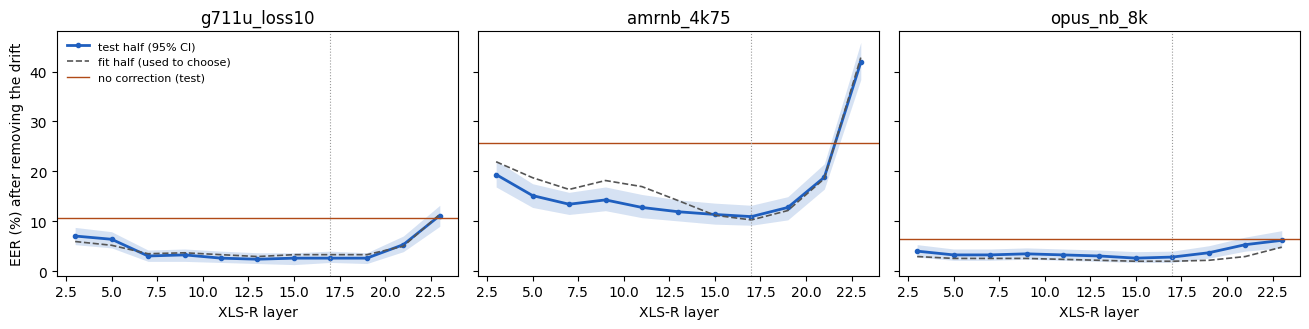

In [12]:
#@title 9 · Choose the layer on the fit half only, then the full layer curve on the test half (about 30-40 min)
import matplotlib.pyplot as plt
SWEEP, VALL = [], {}
for c in DAMAGING:
    Hx, Sx = INSIDE[K][c]
    for l in CFG['CAND_LAYERS']:
        v = (Hx - Hc)[fit, l].mean(0); VALL[(c, l)] = v
        ctx = lambda m, l=l, v=v: P.LayerShift(m, l, -v)
        s_fit = scores_for(f'{c}__shift__L{l}', c, 'fit', ctx)
        s_test = scores_for(f'{c}__shift__L{l}', c, 'test', ctx)
        SWEEP.append(dict(stage=c, layer=l, fit_eer=eer_(s_fit, y[fit]), **ci_eer(s_test, Sx[test]), **op(s_test)))
        r = SWEEP[-1]
        print(f"{c:13s} L{l:2d}  fit EER {100*r['fit_eer']:5.1f}%  test EER {100*r['eer']:5.1f}% [{100*r['eer_lo']:.1f}, {100*r['eer_hi']:.1f}]")
    for part in ('fit',):
        WAV.pop((c, part), None)
SWEEP = pd.DataFrame(SWEEP); SWEEP.to_csv(f'{W3}/layer_sweep.csv', index=False)
NONE = {c: dict(fit_eer=eer_(INSIDE[K][c][1][fit], y[fit]), **ci_eer(INSIDE[K][c][1][test])) for c in DAMAGING}
L_STAGE = {c: int(SWEEP[SWEEP.stage == c].sort_values(['fit_eer', 'layer']).layer.iloc[0]) for c in DAMAGING}
L_STAR = int(SWEEP.groupby('layer').fit_eer.mean().sort_values().index[0])
json.dump(dict(L_STAR=L_STAR, L_STAGE=L_STAGE), open(f'{W3}/chosen_layers.json', 'w'))
print('\nLayer chosen on the fit half (one layer for all stages):', L_STAR, '| per stage:', L_STAGE)

fig, axes = plt.subplots(1, len(DAMAGING), figsize=(4.4 * len(DAMAGING), 3.4), sharey=True)
for ax, c in zip(np.atleast_1d(axes), DAMAGING):
    g = SWEEP[SWEEP.stage == c]
    ax.fill_between(g.layer, 100 * g.eer_lo, 100 * g.eer_hi, color='#1f5fbf', alpha=.18, lw=0)
    ax.plot(g.layer, 100 * g.eer, color='#1f5fbf', lw=2, marker='o', ms=3, label='test half (95% CI)')
    ax.plot(g.layer, 100 * g.fit_eer, color='#555', lw=1.2, ls='--', label='fit half (used to choose)')
    ax.axhline(100 * NONE[c]['eer'], color='#B04A17', lw=1, label='no correction (test)')
    ax.axvline(L_STAR, color='#999', lw=.8, ls=':')
    ax.set_title(c); ax.set_xlabel('XLS-R layer')
np.atleast_1d(axes)[0].set_ylabel('EER (%) after removing the drift'); np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f"{CFG['OUT']}/figures/week3_layer_curve.png", dpi=200); plt.show()

In [13]:
#@title 10 · Baselines at the fit-chosen layer: unpaired shift, NAP, LEACE, CORAL, random, class mix, clean cost (about 15 min)
def nap_affine(D, k):
    # nuisance attribute projection: remove the top-k directions of the paired clean->call change (no mean alignment)
    U = np.linalg.svd(D, full_matrices=False)[2][:k].T
    return (np.eye(D.shape[1], dtype=np.float32) - U @ U.T).astype(np.float32), np.zeros(D.shape[1], np.float32)

def leace_affine(X0, X1, reg=0.1):
    # LEACE (Belrose et al., 2023) for a binary concept (clean = 0, call = 1); shrinkage as for CORAL
    X = np.concatenate([X0, X1]).astype(np.float64); z = np.r_[np.zeros(len(X0)), np.ones(len(X1))]
    mu = X.mean(0); Xc = X - mu
    C = np.cov(Xc.T); C = (1 - reg) * C + reg * np.diag(np.diag(C)) + 1e-6 * np.eye(len(C))
    w, V = np.linalg.eigh(C); w = np.clip(w, 1e-8, None)
    Wm, Wi = (V * w ** -0.5) @ V.T, (V * w ** 0.5) @ V.T
    a = Wm @ (Xc.T @ (z - z.mean()) / len(z)); a /= np.linalg.norm(a)
    M = Wi @ np.outer(a, a) @ Wm                      # x' = x - M (x - mu)
    return (np.eye(len(C)) - M.T).astype(np.float32), (mu @ M.T).astype(np.float32)

rngb = np.random.default_rng(CFG['SEED'] + 1)
fit_idx = np.where(fit)[0]
perm = rngb.permutation(fit_idx); U1, U2 = perm[:len(perm) // 2], perm[len(perm) // 2:]
g_fit, s_fit_idx = np.where(fit & (y == 1))[0], np.where(fit & (y == 0))[0]
def mix(p_gen, n=500):
    n = min(n, int(min(len(g_fit), len(s_fit_idx)) / 0.9))
    ng = int(round(p_gen * n)); return np.concatenate([rngb.choice(g_fit, ng, replace=False), rngb.choice(s_fit_idx, n - ng, replace=False)])
MIX = {0.1: mix(0.1), 0.9: mix(0.9)}

BASE_ROWS, CLEANCOST = [], {}
L = L_STAR
for c in DAMAGING:
    Hx, Sx = INSIDE[K][c]; D = (Hx - Hc)[:, L]
    v = VALL[(c, L)]
    r = rngb.standard_normal(1024).astype(np.float32); r *= np.linalg.norm(v) / np.linalg.norm(r)
    v_unp = Hx[U1, L].mean(0) - Hc[U2, L].mean(0)
    A_c, b_c = P.coral_affine(Hx[fit, L], Hc[fit, L])
    A_l, b_l = leace_affine(Hc[fit, L], Hx[fit, L])
    V = [('channel-supervised mean shift (paired)', c, lambda m: P.LayerShift(m, L, -v), f'{c}__shift__L{L}'),
         ('unpaired mean shift', c, lambda m: P.LayerShift(m, L, -v_unp), f'{c}__unpaired__L{L}'),
         ('LEACE (clean vs call)', c, lambda m: P.LayerAffine(m, L, A_l, b_l), f'{c}__leace__L{L}'),
         ('CORAL (unpaired)', c, lambda m: P.LayerAffine(m, L, A_c, b_c), f'{c}__coral__L{L}'),
         ('random direction, same norm', c, lambda m: P.LayerShift(m, L, -r), f'{c}__random__L{L}')]
    for k_ in (1, 4, 16):
        A_n, b_n = nap_affine(D[fit], k_)
        V.append((f'NAP rank {k_}', c, lambda m, A_n=A_n, b_n=b_n: P.LayerAffine(m, L, A_n, b_n), f'{c}__nap{k_}__L{L}'))
    for p_, idx in MIX.items():
        vm = D[idx].mean(0)
        V.append((f'mean shift, fit set {int(100*p_)}% genuine', c, lambda m, vm=vm: P.LayerShift(m, L, -vm), f'{c}__mix{int(100*p_)}__L{L}'))
    V.append(('clean cost: mean shift applied to clean audio', 'clean', lambda m: P.LayerShift(m, L, -v), f'{c}__cleancost__L{L}'))
    BASE_ROWS.append(dict(stage=c, layer=L, variant='no correction', **ci_eer(Sx[test]), **op(Sx[test])))
    thr_rec = P.eer(Sx[fit & (y == 1)], Sx[fit & (y == 0)])[1]
    BASE_ROWS.append(dict(stage=c, layer=L, variant='recalibrated threshold (labelled)', **ci_eer(Sx[test]), **op(Sx[test], thr_rec)))
    for name, cond, ctx, tag in V:
        s = scores_for(tag, cond, 'test', ctx)
        ref = Sc[test] if cond == 'clean' else Sx[test]
        BASE_ROWS.append(dict(stage=c, layer=L, variant=name, **ci_eer(s, ref), **op(s)))
        if cond == 'clean':
            CLEANCOST[c] = s
        rr = BASE_ROWS[-1]
        print(f"{c:13s} L{L:2d} {name:46s} EER {100*rr['eer']:5.1f}% [{100*rr['eer_lo']:.1f}, {100*rr['eer_hi']:.1f}]  "
              f"real rej {100*rr['real_rejected']:5.1f}%  fakes acc {100*rr['fakes_accepted']:5.1f}%")
    WAV.pop((c, 'test'), None)
BASE_ROWS.append(dict(stage='clean', layer=-1, variant='no correction', **ci_eer(Sc[test]), **op(Sc[test])))
BASE = pd.DataFrame(BASE_ROWS); BASE.to_csv(f'{W3}/baselines_at_chosen_layer.csv', index=False)
display(BASE.assign(**{m: (100 * BASE[m]).round(1) for m in ('eer', 'eer_lo', 'eer_hi', 'real_rejected', 'fakes_accepted', 'hter')})
        [['stage', 'variant', 'eer', 'eer_lo', 'eer_hi', 'real_rejected', 'fakes_accepted', 'hter']])

g711u_loss10  L17 channel-supervised mean shift (paired)         EER   2.6% [1.7, 4.0]  real rej   2.6%  fakes acc   2.6%
g711u_loss10  L17 unpaired mean shift                            EER   2.8% [1.7, 4.4]  real rej   2.9%  fakes acc   2.8%
g711u_loss10  L17 LEACE (clean vs call)                          EER   5.3% [4.0, 7.0]  real rej  19.3%  fakes acc   0.0%
g711u_loss10  L17 CORAL (unpaired)                               EER   4.4% [2.8, 5.7]  real rej   0.9%  fakes acc  21.5%
g711u_loss10  L17 random direction, same norm                    EER   9.4% [7.5, 11.4]  real rej  36.4%  fakes acc   0.4%
g711u_loss10  L17 NAP rank 1                                     EER   7.0% [5.1, 9.2]  real rej   0.0%  fakes acc  64.8%
g711u_loss10  L17 NAP rank 4                                     EER   4.6% [3.2, 5.9]  real rej   0.0%  fakes acc  98.9%
g711u_loss10  L17 NAP rank 16                                    EER   5.1% [3.5, 6.6]  real rej   0.0%  fakes acc  99.6%
g711u_loss10  L17 mean 

,stage,variant,eer,eer_lo,eer_hi,real_rejected,fakes_accepted,hter
0,g711u_loss10,no correction,10.7,9.0,13.0,59.9,0.0,29.9
1,g711u_loss10,recalibrated threshold (labelled),10.7,9.0,13.0,11.6,10.2,10.9
2,g711u_loss10,channel-supervised mean shift (paired),2.6,1.7,4.0,2.6,2.6,2.6
3,g711u_loss10,unpaired mean shift,2.8,1.7,4.4,2.9,2.8,2.8
4,g711u_loss10,LEACE (clean vs call),5.3,4.0,7.0,19.3,0.0,9.6
5,g711u_loss10,CORAL (unpaired),4.4,2.8,5.7,0.9,21.5,11.2
6,g711u_loss10,"random direction, same norm",9.4,7.5,11.4,36.4,0.4,18.4
7,g711u_loss10,NAP rank 1,7.0,5.1,9.2,0.0,64.8,32.4
8,g711u_loss10,NAP rank 4,4.6,3.2,5.9,0.0,98.9,49.5
9,g711u_loss10,NAP rank 16,5.1,3.5,6.6,0.0,99.6,49.8


In [14]:
#@title 11 · The phone-call gate: does it spot calls (including wideband), and the end-to-end error with its mistakes (about 10 min)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GL = CFG['GATE_LAYER']
Xtr = np.concatenate([Hc[fit, GL]] + [INSIDE[K][c][0][fit, GL] for c in DAMAGING])
ytr = np.r_[np.zeros(fit.sum()), np.ones(fit.sum() * len(DAMAGING))]
gate = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced')).fit(Xtr, ytr)

@torch.no_grad()
def gate_feats(cond):
    f = f'{W3}/scores/gatefeat_{cond}_L{GL}.npy'
    if os.path.exists(f):
        return np.load(f)
    m, X, out = model_A(), waves(cond, 'test'), []
    for i in range(0, len(X), CFG['BATCH']):
        with P.LayerTaps(m, [GL]) as tp:
            m(torch.tensor(X[i:i + CFG['BATCH']]).to(dev))
        out.append(tp.store[GL])
    h = np.concatenate(out); np.save(f, h); WAV.pop((cond, 'test'), None)
    return h

EXTRA = [c for c in ('nb_resample', 'bandpass_300_3400', 'g711u', 'amrnb_12k2', 'amrnb_7k4', 'amrnb_5k9', 'gsm_fr',
                     'amrwb_12k65', 'amrwb_23k85', 'opus_wb_16k', 'opus_wb_24k', 'webrtc_only') if c in ALL]
GATE = [dict(condition='clean (should NOT be flagged)', flagged=float(gate.predict(Hc[test, GL]).mean()))]
for c in DAMAGING:
    GATE.append(dict(condition=c, flagged=float(gate.predict(INSIDE[K][c][0][test, GL]).mean())))
for c in EXTRA:
    GATE.append(dict(condition=c, flagged=float(gate.predict(gate_feats(c)).mean())))
    print(f'gate: {c:16s} flagged as call {100*GATE[-1]["flagged"]:5.1f}%')
GATE = pd.DataFrame(GATE); GATE.to_csv(f'{W3}/gate_detection.csv', index=False)

# end-to-end: the correction is applied only where the gate says "call"
E2E = []
g_clean = gate.predict(Hc[test, GL]).astype(bool)
for c in DAMAGING:
    Sx = INSIDE[K][c][1]
    s_fix = scores_for(f'{c}__shift__L{L_STAR}', c, 'test')
    g_call = gate.predict(INSIDE[K][c][0][test, GL]).astype(bool)
    for name, s in (('never correct', Sx[test]), ('always correct', s_fix), ('gated', np.where(g_call, s_fix, Sx[test]))):
        E2E.append(dict(audio=c, policy=name, **ci_eer(s), **op(s)))
    s_cc = CLEANCOST[c]
    for name, s in (('never correct', Sc[test]), ('always correct', s_cc), ('gated', np.where(g_clean, s_cc, Sc[test]))):
        E2E.append(dict(audio=f'clean (fix fitted on {c})', policy=name, **ci_eer(s), **op(s)))
E2E = pd.DataFrame(E2E); E2E.to_csv(f'{W3}/gate_end_to_end.csv', index=False)
display(GATE.assign(flagged=(100 * GATE.flagged).round(1)))
display(E2E.assign(**{m: (100 * E2E[m]).round(1) for m in ('eer', 'real_rejected', 'fakes_accepted', 'hter')})
        [['audio', 'policy', 'eer', 'real_rejected', 'fakes_accepted', 'hter']])

gate: nb_resample      flagged as call 100.0%
gate: bandpass_300_3400 flagged as call  99.9%
gate: g711u            flagged as call 100.0%
gate: amrnb_12k2       flagged as call  99.9%
gate: amrnb_7k4        flagged as call  99.9%
gate: amrnb_5k9        flagged as call  99.9%
gate: gsm_fr           flagged as call 100.0%
gate: amrwb_12k65      flagged as call   2.3%
gate: amrwb_23k85      flagged as call   1.0%
gate: opus_wb_16k      flagged as call   0.6%
gate: opus_wb_24k      flagged as call   0.5%
gate: webrtc_only      flagged as call   0.2%


,condition,flagged
0,clean (should NOT be flagged),0.2
1,g711u_loss10,100.0
2,amrnb_4k75,99.9
3,opus_nb_8k,99.9
4,nb_resample,100.0
5,bandpass_300_3400,99.9
6,g711u,100.0
7,amrnb_12k2,99.9
8,amrnb_7k4,99.9
9,amrnb_5k9,99.9


,audio,policy,eer,real_rejected,fakes_accepted,hter
0,g711u_loss10,never correct,10.7,59.9,0.0,29.9
1,g711u_loss10,always correct,2.6,2.6,2.6,2.6
2,g711u_loss10,gated,2.6,2.6,2.6,2.6
3,clean (fix fitted on g711u_loss10),never correct,0.0,0.0,4.5,2.2
4,clean (fix fitted on g711u_loss10),always correct,0.6,0.0,22.6,11.3
5,clean (fix fitted on g711u_loss10),gated,0.0,0.0,4.5,2.2
6,amrnb_4k75,never correct,25.6,87.1,0.4,43.7
7,amrnb_4k75,always correct,10.9,8.8,13.0,10.9
8,amrnb_4k75,gated,10.9,8.8,13.0,10.9
9,clean (fix fitted on amrnb_4k75),never correct,0.0,0.0,4.5,2.2


In [15]:
#@title 12 · Silence and loudness controls (uses week-2 scores if they exist, otherwise scores them: about 10 min)
SC_ROWS = []
def sc(cond):
    path = f"{FOLDER[K]}/eval__{cond}.csv"
    return score_set(None if os.path.exists(path) else model_A(), EV, cond, FOLDER[K])
ref = {'': sc('clean'), '__rms': sc('clean_rms') if 'clean_rms' in ALL else sc('clean'), '__trim': sc('clean_trim')}
for c in DAMAGING:
    for suf, label in (('', 'as is'), ('__rms', 'loudness-normalised'), ('__trim', 'silence removed')):
        cond = c + suf
        if cond not in ALL:
            continue
        d, r0 = sc(cond), ref[suf]
        m = d.merge(r0[['utt', 'score']], on='utt', suffixes=('', '_ref'))
        b, f = m[m.label == 1], m[m.label == 0]
        fa, miss = P.rates_at(b.score.values, f.score.values, THR)
        SC_ROWS.append(dict(stage=c, control=label, eer=P.eer(b.score.values, f.score.values)[0], real_rejected=fa, fakes_accepted=miss,
                            genuine_shift=float((b.score - b.score_ref).mean()), spoof_shift=float((f.score - f.score_ref).mean())))
SC_ROWS = pd.DataFrame(SC_ROWS); SC_ROWS.to_csv(f'{W3}/shortcut_controls.csv', index=False)
display(SC_ROWS.round(3))
print('Reading: if real callers rejected stays high after loudness matching and silence removal, the failure is not a level or silence shortcut.')

,stage,control,eer,real_rejected,fakes_accepted,genuine_shift,spoof_shift
0,g711u_loss10,as is,0.104,0.592,0.001,-7.332,-0.048
1,g711u_loss10,loudness-normalised,0.127,0.684,0.002,-7.466,-0.066
2,g711u_loss10,silence removed,0.232,0.944,0.001,-5.070,-0.045
3,amrnb_4k75,as is,0.279,0.889,0.002,-8.005,-0.055
4,amrnb_4k75,loudness-normalised,0.219,0.824,0.005,-7.881,-0.069
5,amrnb_4k75,silence removed,0.358,0.997,0.000,-5.199,-0.057
6,opus_nb_8k,as is,0.059,0.260,0.000,-5.401,-0.060
7,opus_nb_8k,loudness-normalised,0.066,0.229,0.004,-5.538,-0.069
8,opus_nb_8k,silence removed,0.153,0.790,0.000,-4.807,-0.059


Reading: if real callers rejected stays high after loudness matching and silence removal, the failure is not a level or silence shortcut.


In [17]:
#@title 13a · ASVspoof 2021 LA loader (labels from data/labels.parquet)
import io, os, json as _json, numpy as np, pandas as pd, soundfile as sf
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download
REPO21 = 'SpeechAntiSpoofingBenchmarks/ASVspoof2021_LA'
D21 = f'{W3}/la21'; os.makedirs(f'{D21}/audio', exist_ok=True); META21 = f'{D21}/meta.csv'
CODECS = ['none', 'alaw', 'pstn', 'g722', 'ulaw', 'gsm', 'opus']
N21 = CFG['N21']
base = lambda s: os.path.splitext(os.path.basename(str(s)))[0]

def flat(row):                       # merge plain columns + any JSON 'notes' column, lowercase keys
    d = {}
    for k, v in row.items():
        if k == 'audio': continue
        if isinstance(v, str) and v.strip().startswith('{'):
            try: d.update({kk.lower(): vv for kk, vv in _json.loads(v).items()}); continue
            except Exception: pass
        if isinstance(v, dict): d.update({kk.lower(): vv for kk, vv in v.items()}); continue
        d[k.lower()] = v
    return d
def get(d, *keys):
    for k in keys:
        for dk, v in d.items():
            if k in dk and v is not None and str(v) not in ('', 'nan'): return v
    return None

files = HfApi().list_repo_files(REPO21, repo_type='dataset')
lab = pq.read_table(hf_hub_download(REPO21, 'data/labels.parquet', repo_type='dataset', local_dir='/tmp/hf21')).to_pandas()
print('labels columns:', list(lab.columns)); print(lab.head(2).T)
L = {}
for r in lab.to_dict('records'):
    d = flat(r); uid = get(d, 'utterance', 'utt', 'file', 'path', 'name', 'id')
    if uid is not None: L[base(uid)] = d
print('labels rows:', len(L))

shards = sorted(f for f in files if f.endswith('.parquet') and 'labels' not in f)
cnt, rows21 = {}, []
full = lambda: all(cnt.get((c, b), 0) >= N21 for c in CODECS for b in (0, 1))
for sh in shards:
    if full(): break
    local = hf_hub_download(REPO21, sh, repo_type='dataset', local_dir='/tmp/hf21')
    pf = pq.ParquetFile(local)
    cols = [c for c in pf.schema_arrow.names if c != 'audio']
    meta = pf.read(columns=cols).to_pandas() if cols else None
    audio = pf.read(columns=['audio']).column('audio')
    pick = []
    for i in range(len(audio)):
        a_path = audio[i]['path'].as_py() if 'path' in audio.type.names else None
        own = flat(meta.iloc[i].to_dict()) if meta is not None else {}
        uid = base(get(own, 'utterance', 'utt', 'file', 'path', 'name', 'id') or a_path or i)
        d = {**L.get(uid, {}), **own}
        cd = str(get(d, 'codec') or '').lower()
        att = str(get(d, 'attack') or '').lower(); key = str(get(d, 'key', 'label') or '').lower()
        bona = 1 if ('bona' in att or 'bona' in key or att in ('-',)) else 0
        trim = str(get(d, 'trim') or 'notrim').lower()
        if cd in CODECS and trim == 'notrim' and cnt.get((cd, bona), 0) < N21:
            cnt[(cd, bona)] = cnt.get((cd, bona), 0) + 1; pick.append((i, uid, d, bona, cd))
    for i, uid, d, bona, cd in pick:
        x, sr = sf.read(io.BytesIO(audio[i]['bytes'].as_py()), dtype='float32')
        if sr != P.SR:
            from scipy.signal import resample_poly; x = resample_poly(x, P.SR, sr).astype(np.float32)
        p = f'{D21}/audio/{uid}.flac'; sf.write(p, x, P.SR)
        rows21.append(dict(utt=uid, speaker=get(d, 'speaker'), codec=cd, transmission=get(d, 'transmission'),
                           attack=get(d, 'attack'), label=bona, path=p))
    os.remove(local); print(f'{sh}: picked {len(pick)}, total {len(rows21)}')
LA21m = pd.DataFrame(rows21); LA21m.to_csv(META21, index=False)
print(LA21m.groupby(['codec', 'label']).size().unstack())
print(LA21m.groupby(['label', 'attack']).size().head(20))

labels columns: ['utterance_id', 'label']
                         0             1
utterance_id  LA_E_1000048  LA_E_1000166
label                    1             1
labels rows: 181566


data/test-00000-of-00024.parquet: reconstructing file:   0%|          |  0.00B /  315MB            

data/test-00000-of-00024.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00024.parquet: picked 1505, total 1505


data/test-00001-of-00024.parquet: reconstructing file:   0%|          |  0.00B /  315MB            

data/test-00001-of-00024.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00024.parquet: picked 175, total 1680
label    0    1
codec          
alaw   120  120
g722   120  120
gsm    120  120
none   120  120
opus   120  120
pstn   120  120
ulaw   120  120
label  attack  
0      A07          66
       A08          56
       A09          62
       A10          69
       A11          72
       A12          64
       A13          70
       A14          56
       A15          66
       A16          67
       A17          64
       A18          67
       A19          61
1      bonafide    840
dtype: int64


label    0    1
codec          
alaw   120  120
g722   120  120
gsm    120  120
none   120  120
opus   120  120
pstn   120  120
ulaw   120  120


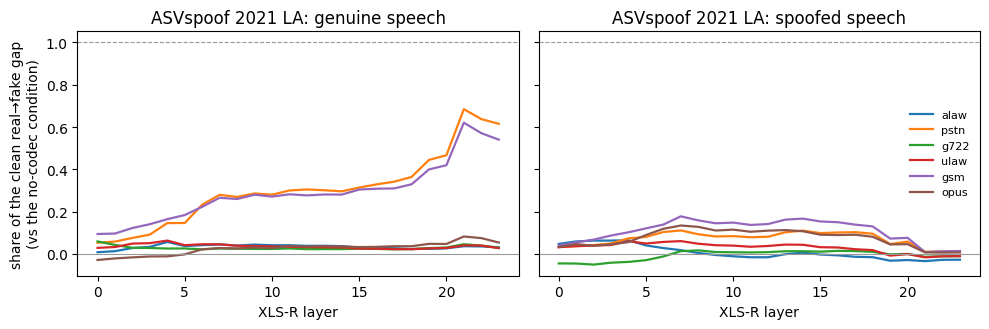

,codec,eer,real_rejected,fakes_accepted,genuine_shift,spoof_shift
0,none,0.000,0.000,0.033,0.000,0.000
1,alaw,0.017,0.008,0.100,-0.193,0.140
2,pstn,0.075,0.133,0.017,-4.550,-0.016
3,g722,0.025,0.008,0.058,-0.149,0.034
4,ulaw,0.008,0.000,0.067,-0.068,0.057
5,gsm,0.083,0.117,0.025,-3.660,-0.029
6,opus,0.008,0.008,0.017,-0.179,-0.025


fake_moves                         genuine_moves                        
layer         3     7     11    17    23            3     7     11    17    23
codec                                                                         
alaw        0.06  0.02 -0.02 -0.01 -0.03          0.03  0.05  0.04  0.03  0.03
g722       -0.04  0.01  0.01  0.01 -0.01          0.03  0.03  0.03  0.02  0.03
gsm         0.09  0.18  0.14  0.14  0.01          0.14  0.27  0.28  0.31  0.54
opus        0.05  0.13  0.10  0.09  0.01         -0.01  0.03  0.04  0.04  0.05
pstn        0.05  0.11  0.08  0.10  0.01          0.09  0.28  0.30  0.34  0.62
ulaw        0.04  0.06  0.03  0.02 -0.01          0.05  0.05  0.03  0.02  0.03

,codec,patch,layer,real_rejected,fakes_accepted,hter,genuine_mean,fake_mean,eer
0,alaw,add 2021 drift,17,0.0,0.045,0.022,4.489,-3.613,0.0
1,alaw,"add random, same norm",17,0.0,0.043,0.021,4.485,-3.618,0.0
2,pstn,add 2021 drift,17,0.0,0.004,0.002,4.037,-3.656,0.0
3,pstn,"add random, same norm",17,0.0,0.049,0.025,4.519,-3.599,0.0
4,g722,add 2021 drift,17,0.0,0.045,0.022,4.509,-3.610,0.0
5,g722,"add random, same norm",17,0.0,0.045,0.022,4.495,-3.610,0.0
6,ulaw,add 2021 drift,17,0.0,0.045,0.022,4.490,-3.619,0.0
7,ulaw,"add random, same norm",17,0.0,0.043,0.021,4.499,-3.618,0.0
8,gsm,add 2021 drift,17,0.0,0.006,0.003,4.093,-3.650,0.0
9,gsm,"add random, same norm",17,0.0,0.051,0.026,4.504,-3.603,0.0


In [18]:
#@title 13 · ASVspoof 2021 LA: does the same mechanism appear on real transmitted audio? (about 30 min with the download)
import io, json as _json
LA21 = None
if CFG['DO_2021']:
    !pip -q install huggingface_hub pyarrow
    D21 = f'{W3}/la21'; os.makedirs(f'{D21}/audio', exist_ok=True)
    META21 = f'{D21}/meta.csv'
    CODECS = ['none', 'alaw', 'pstn', 'g722', 'ulaw', 'gsm', 'opus']
    if not os.path.exists(META21):
        import pyarrow.parquet as pq
        from huggingface_hub import HfApi, hf_hub_download
        REPO21 = 'SpeechAntiSpoofingBenchmarks/ASVspoof2021_LA'
        shards = sorted(f for f in HfApi().list_repo_files(REPO21, repo_type='dataset') if f.endswith('.parquet'))
        print(len(shards), 'parquet shards')
        cnt, rows21 = {}, []
        full = lambda: all(cnt.get((cd, lb), 0) >= CFG['N21'] for cd in CODECS for lb in (0, 1))
        for sh in shards:
            if full():
                break
            local = hf_hub_download(REPO21, sh, repo_type='dataset', local_dir='/tmp/hf21')
            pf = pq.ParquetFile(local)
            meta = pf.read(columns=['path', 'label', 'notes']).to_pandas()
            pick = []
            for i, r in enumerate(meta.itertuples()):
                n = _json.loads(r.notes) if isinstance(r.notes, str) else dict(r.notes)
                bona = 1 if (str(n.get('attack_id', '')).lower() == 'bonafide' or r.label in (0, 'bonafide')) else 0
                cd = str(n.get('codec', '')).lower()
                if cd in CODECS and str(n.get('trim', 'notrim')) == 'notrim' and cnt.get((cd, bona), 0) < CFG['N21']:
                    cnt[(cd, bona)] = cnt.get((cd, bona), 0) + 1
                    pick.append((i, n, bona, cd))
            if pick:
                audio = pf.read(columns=['audio']).column('audio')
                for i, n, bona, cd in pick:
                    a = audio[i].as_py(); x, sr = sf.read(io.BytesIO(a['bytes']), dtype='float32')
                    if sr != P.SR:
                        from scipy.signal import resample_poly
                        x = resample_poly(x, P.SR, sr).astype(np.float32)
                    utt = str(n.get('utterance_id') or os.path.splitext(os.path.basename(meta.path.iloc[i]))[0])
                    p = f'{D21}/audio/{utt}.flac'; sf.write(p, x, P.SR)
                    rows21.append(dict(utt=utt, speaker=n.get('speaker_id'), codec=cd, transmission=n.get('transmission'),
                                       attack=n.get('attack_id'), label=bona, path=p))
            os.remove(local)
            print(f'{sh}: picked {len(pick)}, total {len(rows21)}')
        pd.DataFrame(rows21).to_csv(META21, index=False)
    LA21 = pd.read_csv(META21)
    print(LA21.groupby(['codec', 'label']).size().unstack())

if LA21 is not None:
    # record all 24 layers and the score for every 2021 utterance (no processing: the audio is already transmitted)
    REC21 = f'{D21}/layers.npz'
    if os.path.exists(REC21):
        z = np.load(REC21); H21, S21 = z['H'].astype(np.float32), z['score']
    else:
        m = model_A(); H21 = np.zeros((len(LA21), 24, 1024), np.float16); S21 = np.zeros(len(LA21), np.float32)
        with torch.no_grad():
            for i in range(0, len(LA21), CFG['BATCH']):
                xs = [P.tak_pad(sf.read(p, dtype='float32')[0]) for p in LA21.path.iloc[i:i + CFG['BATCH']]]
                with P.LayerTaps(m, LAYERS_ALL) as tp:
                    s = m(torch.tensor(np.stack(xs)).to(dev))[:, 1].float().cpu().numpy()
                H21[i:i + len(xs)] = np.stack([tp.store[l] for l in LAYERS_ALL], 1).astype(np.float16); S21[i:i + len(xs)] = s
        np.savez(REC21, H=H21, score=S21); H21 = H21.astype(np.float32)
    y21, cd21 = LA21.label.values, LA21.codec.values
    u = Hc[fit & (y == 0)].mean(0) - Hc[fit & (y == 1)].mean(0)            # the SAME clean real->fake axis as in 2019 (fit half)
    base = cd21 == 'none'
    G21, B21 = [], []
    for c in [c for c in CODECS if c != 'none' and (cd21 == c).any()]:
        sel = cd21 == c
        for l in LAYERS_ALL:
            ul = u[l]; gg = ul @ ul
            vb = H21[sel & (y21 == 1), l].mean(0) - H21[base & (y21 == 1), l].mean(0)
            vs = H21[sel & (y21 == 0), l].mean(0) - H21[base & (y21 == 0), l].mean(0)
            G21.append(dict(codec=c, layer=l, genuine_moves=float(vb @ ul / gg), fake_moves=float(vs @ ul / gg),
                            cos_genuine=float(vb @ ul / (np.linalg.norm(vb) * np.sqrt(gg) + 1e-9))))
        b, f = S21[sel & (y21 == 1)], S21[sel & (y21 == 0)]
        fa, miss = P.rates_at(b, f, THR)
        B21.append(dict(codec=c, eer=P.eer(b, f)[0], real_rejected=fa, fakes_accepted=miss,
                        genuine_shift=float(b.mean() - S21[base & (y21 == 1)].mean()), spoof_shift=float(f.mean() - S21[base & (y21 == 0)].mean())))
    b0, f0 = S21[base & (y21 == 1)], S21[base & (y21 == 0)]
    B21.insert(0, dict(codec='none', eer=P.eer(b0, f0)[0], real_rejected=P.rates_at(b0, f0, THR)[0], fakes_accepted=P.rates_at(b0, f0, THR)[1], genuine_shift=0.0, spoof_shift=0.0))
    G21, B21 = pd.DataFrame(G21), pd.DataFrame(B21)
    G21.to_csv(f'{W3}/la21_geometry.csv', index=False); B21.to_csv(f'{W3}/la21_behaviour.csv', index=False)

    # transplant: add each real 2021 codec drift (label-free, all utterances) to CLEAN 2019 test audio at the chosen layer
    T21 = []
    rng21 = np.random.default_rng(CFG['SEED'] + 2)
    for c in B21.codec:
        if c == 'none':
            continue
        sel = cd21 == c
        v21 = H21[sel, L_STAR].mean(0) - H21[base, L_STAR].mean(0)
        r = rng21.standard_normal(1024).astype(np.float32); r *= np.linalg.norm(v21) / np.linalg.norm(r)
        for name, vec in (('add 2021 drift', v21), ('add random, same norm', r)):
            s = scores_for(f'la21_{c}__{name.split()[1]}__L{L_STAR}', 'clean', 'test', lambda m, vec=vec: P.LayerShift(m, L_STAR, vec))
            T21.append(dict(codec=c, patch=name, layer=L_STAR, **op(s), eer=eer_(s, YT)))
    T21 = pd.DataFrame(T21); T21.to_csv(f'{W3}/la21_transplant.csv', index=False)

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
    for c in G21.codec.unique():
        g = G21[G21.codec == c]
        axes[0].plot(g.layer, g.genuine_moves, lw=1.6, label=c); axes[1].plot(g.layer, g.fake_moves, lw=1.6, label=c)
    for ax, t in zip(axes, ('genuine speech', 'spoofed speech')):
        ax.axhline(0, color='#999', lw=.8); ax.axhline(1, color='#999', lw=.8, ls='--'); ax.set_title(f'ASVspoof 2021 LA: {t}'); ax.set_xlabel('XLS-R layer')
    axes[0].set_ylabel('share of the clean real→fake gap\n(vs the no-codec condition)'); axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(f"{CFG['OUT']}/figures/week3_la21_drift.png", dpi=200); plt.show()
    display(B21.round(3)); display(G21[G21.layer.isin([3, 7, 11, 17, 23])].pivot_table(index='codec', columns='layer', values=['genuine_moves', 'fake_moves']).round(2))
    display(T21.round(3))

In [20]:
#@title 14 · Summary to send to Claude (copy this box or send fyp_pilot/week3/week3_summary.txt)
import io as _io
buf = _io.StringIO(); pr = lambda *a: print(*a, file=buf)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
pr('WEEK 3 SUMMARY'); pr('chosen layer (fit half, one for all stages):', L_STAR, '| per stage:', L_STAGE)
pr('\nNO CORRECTION (test):'); [pr(f'  {c}: EER {100*NONE[c]["eer"]:.1f}% [{100*NONE[c]["eer_lo"]:.1f}, {100*NONE[c]["eer_hi"]:.1f}] | fit EER {100*NONE[c]["fit_eer"]:.1f}%') for c in DAMAGING]
pct = lambda df, cols: df.assign(**{m: (100 * df[m]).round(1) for m in cols if m in df})
pr('\nLAYER SWEEP (%):'); pr(pct(SWEEP, ['fit_eer', 'eer', 'eer_lo', 'eer_hi', 'd_eer', 'd_lo', 'd_hi', 'real_rejected', 'fakes_accepted', 'hter'])
   [['stage', 'layer', 'fit_eer', 'eer', 'eer_lo', 'eer_hi', 'd_eer', 'd_lo', 'd_hi', 'real_rejected', 'fakes_accepted']].to_string(index=False))
pr('\nBASELINES AT THE CHOSEN LAYER (%):'); pr(pct(BASE, ['eer', 'eer_lo', 'eer_hi', 'd_eer', 'd_lo', 'd_hi', 'real_rejected', 'fakes_accepted', 'hter'])
   [['stage', 'variant', 'eer', 'eer_lo', 'eer_hi', 'd_eer', 'd_lo', 'd_hi', 'real_rejected', 'fakes_accepted', 'hter']].to_string(index=False))
pr('\nGATE (share flagged as call, %):'); pr(pct(GATE, ['flagged']).to_string(index=False))
pr('\nGATED END-TO-END (%):'); pr(pct(E2E, ['eer', 'real_rejected', 'fakes_accepted', 'hter'])[['audio', 'policy', 'eer', 'real_rejected', 'fakes_accepted', 'hter']].to_string(index=False))
pr('\nSILENCE / LOUDNESS CONTROLS:'); pr(SC_ROWS.round(3).to_string(index=False))
if LA21 is not None:
    pr('\nASVSPOOF 2021 LA, n per codec and class:'); pr(LA21.groupby(['codec', 'label']).size().unstack().to_string())
    pr('\n2021 BEHAVIOUR:'); pr(B21.round(3).to_string(index=False))
    pr('\n2021 GEOMETRY (all layers):'); pr(G21.round(3).to_string(index=False))
    pr('\n2021 TRANSPLANT INTO CLEAN 2019 AUDIO:'); pr(T21.round(3).to_string(index=False))
s = buf.getvalue(); open(f'{W3}/week3_summary.txt', 'w').write(s); print(s)
print('\nSaved: fyp_pilot/week3/week3_summary.txt  |  figures: fyp_pilot/figures/week3_*.png')

WEEK 3 SUMMARY
chosen layer (fit half, one for all stages): 17 | per stage: {'g711u_loss10': 13, 'amrnb_4k75': 17, 'opus_nb_8k': 15}

NO CORRECTION (test):
  g711u_loss10: EER 10.7% [9.0, 13.0] | fit EER 10.1%
  amrnb_4k75: EER 25.6% [22.8, 28.3] | fit EER 29.8%
  opus_nb_8k: EER 6.4% [4.9, 8.1] | fit EER 5.2%

LAYER SWEEP (%):
       stage  layer  fit_eer  eer  eer_lo  eer_hi  d_eer  d_lo  d_hi  real_rejected  fakes_accepted
g711u_loss10      3      5.9  7.0     5.3     8.8   -3.7  -5.3  -2.4           38.6             0.0
g711u_loss10      5      5.2  6.4     4.6     7.9   -4.3  -6.2  -3.0           25.2             0.0
g711u_loss10      7      3.5  3.0     1.9     4.2   -7.7  -9.7  -5.9            9.0             0.6
g711u_loss10      9      3.7  3.2     1.9     4.4   -7.5  -9.5  -5.8           10.1             0.4
g711u_loss10     11      3.3  2.6     1.7     4.0   -8.1  -9.9  -6.1            7.2             0.4
g711u_loss10     13      2.9  2.4     1.5     3.7   -8.3 -10.2  -6.3  

In [2]:
# ============ CELL B (optional, ~30 min): 20 random directions at layer 17 ============
rng20 = np.random.default_rng(CFG['SEED'] + 100)
L = L_STAR; R = []
for c in DAMAGING:
    Hx, Sx = INSIDE[K][c]; v = VALL[(c, L)]
    for j in range(20):
        r = rng20.standard_normal(1024).astype(np.float32); r *= np.linalg.norm(v) / np.linalg.norm(r)
        s = scores_for(f'{c}__rand{j}__L{L}', c, 'test', lambda m, r=r: P.LayerShift(m, L, -r))
        R.append(dict(stage=c, draw=j, eer=eer_(s, YT), **op(s)))
    WAV.pop((c, 'test'), None)
R = pd.DataFrame(R); R.to_csv(f'{W3}/random_draws_L{L}.csv', index=False)
print(R.groupby('stage')[['eer', 'real_rejected', 'fakes_accepted', 'hter']].agg(['mean', 'std', 'min', 'max']).mul(100).round(1))

SystemExit: week3 folder is gone: the session ended. Tell Claude.

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
# ============ CELL A: export everything GitHub needs (run first, ~1 min) ============
# Needs the week-3 Kaggle session still alive (fit, test, y, EV, CFG in memory).
import glob, os, zipfile, numpy as np, pandas as pd
W3 = f"{CFG['OUT']}/week3"
ids = EV.utt.values; part = {'fit': fit, 'test': test}
rows = []
for f in sorted(glob.glob(f'{W3}/scores/*__*.npy')):
    tag, prt = os.path.basename(f)[:-4].rsplit('__', 1)
    if prt not in part: continue
    s = np.load(f); m = part[prt]
    if s.ndim != 1 or len(s) != m.sum(): continue          # skips gate activations (2-D)
    rows.append(pd.DataFrame(dict(tag=tag, part=prt, utt=ids[m], label=y[m], score=s)))
pd.concat(rows).to_csv(f'{W3}/per_utterance_scores_week3.csv.gz', index=False)
pd.DataFrame(dict(utt=ids, label=y, half=np.where(fit, 'fit', 'test'))).to_csv(f'{W3}/fit_test_split.csv', index=False)
out = '/kaggle/working/week3_for_github.zip'
with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f'{W3}/*.csv') + glob.glob(f'{W3}/*.csv.gz') + glob.glob(f'{W3}/*.json') + glob.glob(f'{W3}/*.txt'):
        z.write(f, os.path.relpath(f, CFG['OUT']))
print(len(rows), 'score sets ->', out, os.path.getsize(out) // 1024, 'KB')
# Then: right-hand panel > Output > week3_for_github.zip > download.